# HYROX 대회 기록 분석 : 전처리

**중복·0초 구간·구간 이상 기록의 제외 규칙을 정하고, 분석용 데이터(`clean`)를 생성하는 단계**

## 개요
- 목적: 중복·오류 기록의 제외 규칙 설정 및 분석용 데이터 생성
- 데이터: 01에서 저장한 원본 CSV 92,374건(34열). 분석 범위는 open·pro 부문
- 환경: Python 3.12.15 / pandas 3.0.6 / scikit-learn 1.9.1 (conda `hyrox-analysis`)
- 도구: VS Code, Claude

## 제외 원칙
- 데이터상 존재할 수 없는 값(0초 구간 등): 제외
- 실제 기록일 가능성이 있는 극단값: 근거와 영향 건수를 확인한 뒤 제외 여부 판단
- `roxzone_8`: 열은 있으나 open·pro 전 기록(61,832건)이 0초인 값 없는 구간(01 4절). 마지막 스테이션 뒤가 결승선인 경기 규격과 일치하여 0초 판단 대상에서 제외
- 선수 식별 열이 없어 이상 원인은 모두 추정으로 표기

## 구성
1. 데이터 불러오기
   - 작업: 01에서 저장한 CSV를 읽고 완주 시간(`total_time`)을 초 단위로 변환한 뒤 open·pro 부문 추출
   - 도출: 전처리 대상 `sub`
2. 빠른 완주 기록 탐색
   - 작업: 완주 시간과 런 평균 속도가 빠른 기록 확인
   - 도출: 이상값 후보
3. 중복 기록 확인·제외
   - 작업: 중복 기록 확인 및 제외
   - 도출: 중복 제외 후 데이터
4. 구간 0초 기록 확인·제외
   - 작업: 구간 열을 초 단위로 변환하고 유형별 전체 열과의 일치를 확인한 뒤, `roxzone_8`을 뺀 구간 열의 0초 기록 제외
   - 도출: 0초 구간 제외 후 데이터
5. 구간 이상 기록 탐색·제외
   - 작업: 런 구간 중 최댓값이 자기 중앙값의 5배 이상인 기록 탐색 및 제외
   - 도출: 분석용 데이터 `clean`
6. 전처리 결과 요약
   - 작업: 단계별 제외 건수 정리, 전처리 전후 완주 시간 통계 비교, `clean` 저장, 느린 쪽 끝 5건 확인
   - 도출: 전처리 전후 기록 수와 분석용 데이터 `clean`

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML  # 표 가운데 정렬용 HTML 출력

plt.rc("font", family="Malgun Gothic")  # 한글 표시 오류 방지를 위한 폰트 지정(Windows 기준)
plt.rc("axes", unicode_minus=False)  # 음수 부호(-) 표시 오류 방지

## 1. 데이터 불러오기

**핵심:** 01에서 저장한 CSV를 불러와 완주 시간을 초 단위로 변환하고, 분석 대상(open·pro 부문)을 추출

### 작업 내용
- CSV 읽기: 01에서 엑셀 읽기에 지연이 있어 저장해 둔 `hyrox_results.csv` 사용
- 완주 시간 `total_time` → `total_sec` 변환 (구간 열은 4절에서 변환)
- 분석 대상: open·pro 부문을 `sub`로 추출 (나머지 부문 제외)
- 원본 `df`는 유지하고, 단계별 결과를 `step1`, `step2`, `clean`으로 나눠 저장

### 확인 포인트
- `df.shape`와 01에서 저장한 CSV의 기록 수·열 수(변환 열 1개 추가)의 일치 여부
- open·pro 부문의 기록 수

In [20]:
def to_seconds(t):
    """'hh:mm:ss' 형태를 초 단위 정수로 변환"""
    h, m, s = map(int, str(t).split(":"))
    return h * 3600 + m * 60 + s

# notebooks/ 폴더 기준 상대 경로로 data/ 폴더 접근
df = pd.read_csv("../data/hyrox_results.csv")
df["total_sec"] = df["total_time"].apply(to_seconds)
sub = df[df["division"].isin(["open", "pro"])].copy()  # 이후 열 추가 시 경고 방지를 위해 복사본 사용

print("df.shape:", df.shape)
print("open·pro 기록 수(건):", len(sub))

df.shape: (92374, 35)
open·pro 기록 수(건): 61832


### 결과
- `df.shape` (92374, 35): 01에서 저장한 CSV 34열에 `total_sec` 1열 추가
- open·pro 기록 수 61,832건

### 한 줄 정리
- 01에서 저장한 CSV 92,374건을 불러와 완주 시간을 초 단위로 변환하고, 분석 대상 open·pro 부문 61,832건을 추출함

## 2. 빠른 완주 기록 탐색

**핵심:** 완주 시간이 짧은 기록을 완주 시간과 런 평균 속도 기준으로 확인하여 이상값 후보를 파악

### 작업 내용
- 01에서 확인한 0초 기록 외에 빠른 쪽 기록도 점검
- 완주 시간 40~60분 기록을 빠른 순으로 확인하고, 40~55분 구간을 확대한 히스토그램 작성
- 런 평균 속도(분/km) 계산: `run_time` ÷ 8km ÷ 60 (런 8구간 합 기준, 스테이션 제외)
  - 8km는 HYROX 공개 규격(런 1km × 8) 기준이며, 데이터에는 거리 열이 없음
- 런 평균 속도가 빠른 순 30건 확인, 기준 후보(3.0 / 3.25 / 3.5분/km)별 건수 비교, 4.5분/km 미만 확대 히스토그램 작성

### 확인 포인트
- 완주 시간 분포의 빠른 쪽에서 값이 끊기는 지점 유무
- 빠른 쪽 기록의 구간 구성(런·스테이션·록스존)에서 비정상 값 유무
- 런 평균 속도 분포에서 다른 기록과 떨어진 값 유무
- 속도 기준 후보별 해당 건수

In [21]:
def to_mmss_pace(minutes):
    """소수 분(분/km)을 'm:ss' 형식으로 변환"""
    sec = int(round(minutes * 60))
    return f"{sec // 60}:{sec % 60:02d}"

sub["런 속도(분/km)"] = sub["run_time"].apply(to_seconds) / 8 / 60  # 런 8구간 합 ÷ 8km

fast = sub[(sub["total_sec"] >= 40 * 60) & (sub["total_sec"] < 60 * 60)].copy()
fast["런 속도(분:초/km)"] = fast["런 속도(분/km)"].apply(to_mmss_pace)
print("40~60분 기록 수(건):", len(fast))
print(fast.sort_values("total_sec")[["division", "total_time", "run_time", "work_time", "roxzone_time", "런 속도(분:초/km)"]].head(30).to_string())

40~60분 기록 수(건): 215
      division total_time  run_time work_time roxzone_time 런 속도(분:초/km)
59460      pro   00:45:55  00:20:14  00:14:59     00:10:42         2:32
40676      pro   00:51:13  00:51:13  00:00:00     00:00:00         6:24
85777      pro   00:53:36  00:21:18  00:26:50     00:05:28         2:40
33150      pro   00:54:07  00:27:41  00:22:18     00:04:08         3:28
47093     open   00:54:26  00:28:02  00:21:57     00:04:27         3:30
22680     open   00:54:27  00:27:45  00:21:03     00:05:39         3:28
22631     open   00:54:27  00:27:45  00:21:03     00:05:39         3:28
44869     open   00:54:53  00:26:53  00:24:23     00:03:37         3:22
13729     open   00:54:54  00:27:44  00:23:37     00:03:33         3:28
91638      pro   00:55:09  00:29:19  00:23:23     00:02:27         3:40
79041     open   00:55:40  00:29:28  00:22:08     00:04:04         3:41
83630      pro   00:56:07  00:29:25  00:23:44     00:02:58         3:41
25323      pro   00:56:13  00:30:00  00:23:1

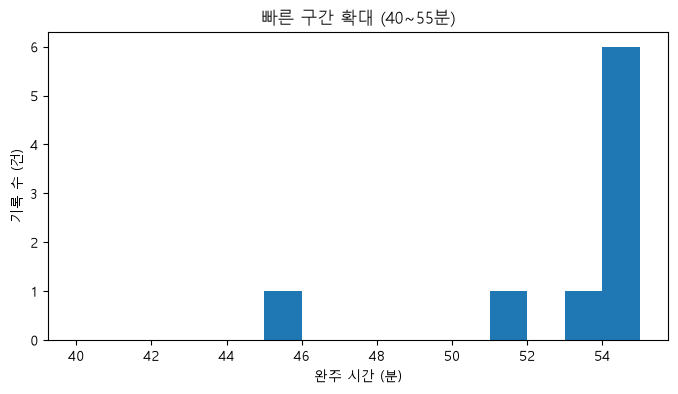

In [22]:
plt.figure(figsize=(8, 4))
plt.hist(sub.loc[sub["total_sec"].between(40 * 60, 55 * 60), "total_sec"] / 60, bins=range(40, 56))  # 확대 구간 40~55분, 1분 간격
plt.xlabel("완주 시간 (분)")
plt.ylabel("기록 수 (건)")
plt.title("빠른 구간 확대 (40~55분)")
plt.show()

      division total_time  run_time 런 속도(분:초/km)
59444      pro   00:00:00  00:00:00         0:00
51952     open   00:00:00  00:00:00         0:00
67232     open   00:00:00  00:00:00         0:00
44566      pro   00:00:00  00:00:00         0:00
4248       pro   00:00:00  00:00:00         0:00
76962     open   00:00:00  00:00:00         0:00
67396     open   00:00:00  00:00:00         0:00
67114      pro   00:00:00  00:00:00         0:00
9841       pro   00:24:08  00:12:54         1:37
9819       pro   00:24:08  00:12:54         1:37
59460      pro   00:45:55  00:20:14         2:32
85777      pro   00:53:36  00:21:18         2:40
4486      open   00:58:07  00:25:20         3:10
42326     open   01:40:04  00:26:45         3:21
44869     open   00:54:53  00:26:53         3:22
52389     open   01:58:40  00:26:55         3:22
44567      pro   00:58:19  00:27:00         3:22
80166      pro   02:03:39  00:27:26         3:26
36400     open   01:05:08  00:27:35         3:27
41114     open   01:

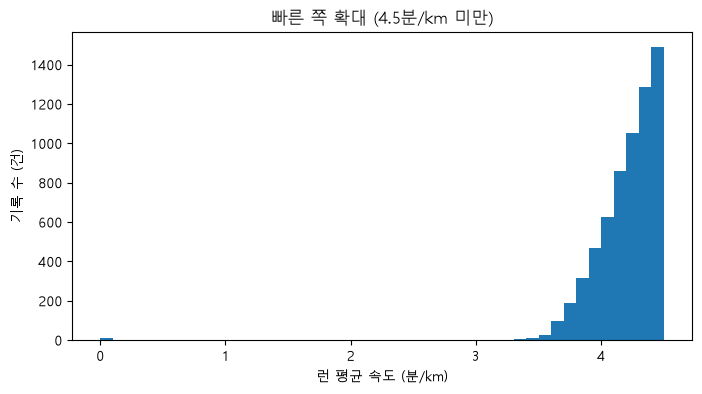

In [23]:
# 빠른 쪽 끝 30건
low = sub.sort_values("런 속도(분/km)").head(30).copy()
low["런 속도(분:초/km)"] = low["런 속도(분/km)"].apply(to_mmss_pace)
print(low[["division", "total_time", "run_time", "런 속도(분:초/km)"]].to_string())

# 기준 후보별 건수
for th in [3.0, 3.25, 3.5]:
    print(f"{th}분/km 미만(건):", (sub["런 속도(분/km)"] < th).sum())

# 빠른 쪽 확대 히스토그램
plt.figure(figsize=(8, 4))
plt.hist(sub.loc[sub["런 속도(분/km)"] < 4.5, "런 속도(분/km)"], bins=[x / 10 for x in range(0, 46)])  # 확대 구간 0~4.5분/km, 0.1 간격
plt.xlabel("런 평균 속도 (분/km)")
plt.ylabel("기록 수 (건)")
plt.title("빠른 쪽 확대 (4.5분/km 미만)")
plt.show()

### 결과
- 완주 시간 40~60분 기록 215건. 54분 이전은 3건(45:55, 51:13, 53:36)이며 54:07부터 기록이 이어지고, 40~45분 기록은 없음
- 51:13은 `run_time`이 완주 시간과 같고 스테이션·록스존 0초, 45:55는 록스존 10:42
- 런 평균 속도 3:00/km 미만 12건: 0초 기록 8건, 24:08 2건(1:37/km), 45:55(2:32/km), 53:36(2:40/km). 이후 값은 3:10, 3:21, 3:22, 3:26 순으로 이어짐
- 히스토그램(0.1분/km 간격): 0분/km 근처에 작은 막대가 있고, 3.5분/km 미만은 막대가 거의 보이지 않으며 4.5분/km 쪽으로 갈수록 건수 증가

**런 평균 속도 기준별 기록 수**

| 런 평균 속도 | 기록 수 |
|---|---|
| 3.0분/km 미만 | 12건 |
| 3.25분/km 미만 | 13건 |
| 3.5분/km 미만 | 29건 |

- 같은 기록이 두 번 나오는 경우(24:08, 54:27, 56:13)가 있으며 3절에서 중복 기록으로 확인됨

### 추정·한계
- 8km를 평균 3:00/km 미만으로 달린 기록은 현실성이 낮은 것으로 추정 (공식 기록과 비교한 것은 아니며, 8km는 공개 규격 기준이고 거리는 데이터에서 확인한 값이 아님)
- 3:00/km 미만 12건의 원인(기록 누락, 입력 오류 등)은 데이터만으로 구분 불가
- 3:00/km는 판단으로 둔 후보 기준이며 분포에 뚜렷한 경계는 없음
- 런 평균 속도는 `run_time` 하나로 계산하므로 구간 간 불일치는 이 절에서 확인 불가 (4절에서 구간 열과 비교)

### 한 줄 정리
- 런 평균 속도 3:00/km 미만 12건(0초 기록 8건 포함)을 이상값 후보로 확인함

## 3. 중복 기록 확인·제외

**핵심:** 모든 열이 같은 기록을 확인하고 첫 기록만 남겨 중복 기록 제외

### 작업 내용
- 선수 식별 열이 없어 모든 열(구간 기록 24개 포함)이 같은 기록을 중복으로 판단
- 중복 그룹에 속한 전체 기록과 첫 기록을 뺀 제외 대상 기록의 수 확인
- 제외 방식: `drop_duplicates()`로 첫 기록만 유지

### 확인 포인트
- 중복 그룹에 속한 기록 수와 제외 대상 기록 수
- 중복 그룹의 크기 (2건 외 3건 이상 묶음의 존재 여부)

In [24]:
dup = sub[sub.duplicated(keep=False)]  # 모든 열(추가한 total_sec, 런 속도 포함)이 같은 기록
print("중복 그룹에 속한 기록 수(건):", len(dup), "/ 제외 대상(첫 기록 제외):", sub.duplicated().sum())
print(dup.sort_values(["total_sec", "event_id"])[["event_id", "division", "gender", "nationality", "age_group", "total_time"]].head(20).to_string())

중복 그룹에 속한 기록 수(건): 3522 / 제외 대상(첫 기록 제외): 1783
          event_id division gender nationality age_group total_time
9819   2EFMS4JI2CB      pro   male         NOR     16-24   00:24:08
9841   2EFMS4JI2CB      pro   male         NOR     16-24   00:24:08
22631  2EFMS4JI3AD     open   male         GBR     16-24   00:54:27
22680  2EFMS4JI3AD     open   male         GBR     16-24   00:54:27
25323  JGDMS4JI461      pro   male         AUT     30-34   00:56:13
25345  JGDMS4JI461      pro   male         AUT     30-34   00:56:13
30375  JGDMS4JI473     open   male         GER     16-24   00:57:18
30425  JGDMS4JI473     open   male         GER     16-24   00:57:18
4247   2EFMS4JI2A9      pro   male         USA     30-34   00:57:45
4280   2EFMS4JI2A9      pro   male         USA     30-34   00:57:45
4281   2EFMS4JI2A9      pro   male         USA     30-34   00:57:45
27506  JGDMS4JI46A      pro   male         GER     30-34   00:58:15
27556  JGDMS4JI46A      pro   male         GER     30-34   00:58:15
1

In [25]:
n0 = len(sub)  # 제외 전 기록 수
step1 = sub.drop_duplicates().copy()  # 첫 기록만 유지
print(f"중복 제외: {n0} → {len(step1)} (-{n0 - len(step1)}건)")

중복 제외: 61832 → 60049 (-1783건)


### 결과
- 모든 열이 같은 기록 3,522건, 첫 기록을 제외한 제외 대상 1,783건
- 표시한 20건(완주 시간 빠른 순)에는 2건 묶음과 3건 묶음이 모두 있음
- 중복 제외: 61,832 → 60,049건 (-1,783건, 전체의 약 2.9%)

### 추정·한계
- 선수 식별 열이 없어 동일 기록의 중복 등재인지, 서로 다른 선수의 일치인지 구분 불가. 모든 구간 기록이 초 단위까지 일치하여 중복 등재로 추정
- 중복이 특정 대회에 몰려 있는지는 확인하지 않음
- 표시한 20건은 완주 시간이 빠른 순이라 전체 중복의 구성을 대표하지 않음

### 한 줄 정리
- 모든 열이 같은 기록 중 첫 기록을 뺀 1,783건을 중복으로 보고 제외하여 60,049건이 남음

## 4. 구간 0초 기록 확인·제외

**핵심:** 런·스테이션·록스존 구간에 0초가 있는 기록을 확인하여 제외

### 작업 내용
- 대상: 3절에서 중복을 제외한 데이터 `step1`
- 구간 열 24개와 유형별 전체 열 3개(`run_time`, `work_time`, `roxzone_time`)를 초 단위로 변환
- 0초 판단 대상 열: 런 `run_1~8`, 스테이션 `work_1~8`, 록스존 `roxzone_1~7`
  - `roxzone_8`은 open·pro 전 기록이 0초인 값 없는 구간이라 제외 (01 4절)
- 구간 열 8개의 합과 유형별 전체 열의 일치 확인: 2절 런 평균 속도가 `run_time` 하나로 계산되어 구간 열과의 불일치를 확인하지 못함
- 구간 중 하나라도 0초인 기록 제외
- 2절의 런 평균 속도 3:00/km 미만 기록과 0초 기록의 중복 확인: 속도 기준에만 해당하는 기록이 있으면 속도 규칙을 별도 적용

### 확인 포인트
- 구간 열의 합과 유형별 전체 열의 불일치 건수
- 구간 유형(런·스테이션·록스존)별 0초 포함 건수
- 속도 기준에만 해당하는 기록 유무

In [26]:
# 구간 열 24개 + 유형별 전체 열 3개를 초 단위로 변환
time_cols = [f"{k}_{i}" for k in ["run", "work", "roxzone"] for i in range(1, 9)]
time_cols += ["run_time", "work_time", "roxzone_time"]
for c in time_cols:
    step1[c + "_sec"] = step1[c].apply(to_seconds)

run_cols = [f"run_{i}_sec" for i in range(1, 9)]
work_cols = [f"work_{i}_sec" for i in range(1, 9)]
rox_cols = [f"roxzone_{i}_sec" for i in range(1, 8)]  # 0초 판단 열: roxzone_8은 open·pro 전 기록이 0초라 제외

# 구간 열 8개의 합과 유형별 전체 열 비교 (roxzone_8 포함 8개 구간 사용)
for k in ["run", "work", "roxzone"]:
    diff = (step1[[f"{k}_{i}_sec" for i in range(1, 9)]].sum(axis=1) - step1[f"{k}_time_sec"]).abs()
    print(f"{k}_time 합계 불일치(건):", (diff > 0).sum())

run_time 합계 불일치(건): 0
work_time 합계 불일치(건): 0
roxzone_time 합계 불일치(건): 0


In [27]:
# 구간 유형별 0초 포함 여부
zero_by_type = pd.DataFrame({
    "런": (step1[run_cols] == 0).any(axis=1),
    "스테이션": (step1[work_cols] == 0).any(axis=1),
    "록스존(1~7)": (step1[rox_cols] == 0).any(axis=1),
})
print("구간 유형별 0초 포함 기록 수(건):")
print(zero_by_type.sum())

zero_flag = zero_by_type.any(axis=1)  # 하나라도 0초
pace_flag = step1["런 속도(분/km)"] < 3.0  # 런 평균 속도 3:00/km 미만 (2절)
print("0초 포함(건):", zero_flag.sum())
print("런 속도 3분/km 미만(건):", pace_flag.sum(), "/ 0초와 겹침:", (zero_flag & pace_flag).sum(), "/ 속도 기준에만 해당:", (pace_flag & ~zero_flag).sum())

step2 = step1[~zero_flag].copy()
print(f"구간 0초 제외: {len(step1)} → {len(step2)} (-{zero_flag.sum()}건)")

구간 유형별 0초 포함 기록 수(건):
런            38
스테이션        104
록스존(1~7)     26
dtype: int64
0초 포함(건): 125
런 속도 3분/km 미만(건): 11 / 0초와 겹침: 11 / 속도 기준에만 해당: 0
구간 0초 제외: 60049 → 59924 (-125건)


### 결과
- 구간 열 8개의 합과 유형별 전체 열 불일치: 0건 (런·스테이션·록스존 모두)
- 구간 0초 제외: 60,049 → 59,924건 (-125건)
- 런 평균 속도 3:00/km 미만 11건은 모두 0초 기록과 겹침 (속도 기준에만 해당하는 기록 0건)
- 2절의 12건보다 1건 적음: 24:08 동일 기록 2건(9819, 9841)이 3절에서 1건으로 줄어듦

**구간 유형별 0초 포함 기록 수**

| 유형 | 0초 포함 기록 수 |
|---|---|
| 런 | 38건 |
| 스테이션 | 104건 |
| 록스존(1~7구간) | 26건 |

- 한 기록이 여러 유형에 해당할 수 있어 유형별 합계(168건)와 제외 건수(125건)가 다름

### 추정·한계
- 0초 구간의 원인(기록 누락, 측정 오류 등)은 데이터만으로 구분 불가
- 구간 열의 합이 유형별 전체 열과 모두 일치하여, 0초 구간의 시간이 다른 구간에 합산됐는지는 구분 불가
- 구간 하나만 0초이고 완주 시간이 정상 범위인 기록의 건수는 확인하지 않음

### 한 줄 정리
- 구간 중 0초가 있는 125건을 제외했고, 런 평균 속도 3:00/km 미만 11건은 모두 여기에 포함되어 속도 규칙은 따로 두지 않음

## 5. 구간 이상 기록 탐색·제외

**핵심:** 런 구간 중 한 구간만 비정상적으로 긴 기록을 확인하여 제외 기준 설정

### 작업 내용
- 대상: 4절에서 0초 구간을 제외한 데이터 `step2`
- 런 비율: `run_time` ÷ 해당 기록의 런 8구간 중앙값
- 탐색용 극단 기록: 런 비율이 6.5배 미만 또는 12배 초과인 기록 (제외 기준과 별개로 패턴 확인에만 사용)
- 구간 이상 정의: 런 구간 중 최댓값이 자기 런 구간 중앙값의 5배 이상인 기록
  - 절대 시간(N분 초과) 기준은 완주 시간이 느린 기록의 실제 구간까지 제외할 수 있어 상대 기준 사용
- 5배는 분포에 뚜렷한 경계가 없어 판단으로 설정하고, 4배·6배와 건수를 비교
- 제외한 기록은 `removed_big`에 보관 (모델 단계에서 제외·유지 결과 비교에 사용)

### 확인 포인트
- 런 비율 분포(중앙값, 1%·99%)와 범위별 이탈 건수
- 극단 기록의 구간별 패턴과 대회별 분포
- 런 구간 최댓값(분)의 분포에서 값이 끊기는 지점 유무
- 기준을 4배·5배·6배로 바꿀 때 건수 변화

In [28]:
step2["런_중앙값(초)"] = step2[run_cols].median(axis=1)
step2["런비율"] = step2["run_time_sec"] / step2["런_중앙값(초)"]  # 총 런 시간 ÷ 런 구간 중앙값

print(step2["런비율"].describe(percentiles=[0.01, 0.5, 0.99]).round(2))

# 범위별 이탈 건수 (미만 + 초과)
ranges = [(7, 9), (6.5, 10), (6, 12)]
out = pd.DataFrame({
    "범위": [f"{lo}~{hi}배" for lo, hi in ranges],
    "이탈(건)": [(~step2["런비율"].between(lo, hi)).sum() for lo, hi in ranges],
    "미만(건)": [(step2["런비율"] < lo).sum() for lo, hi in ranges],
    "초과(건)": [(step2["런비율"] > hi).sum() for lo, hi in ranges],
})
print(out.to_string(index=False))

cols = ["division", "total_time", "run_time", "런비율"]
print(step2.sort_values("런비율")[cols].head(10).to_string())
print(step2.sort_values("런비율")[cols].tail(10).to_string())

count    59924.00
mean         8.00
std          0.35
min          6.04
1%           7.47
50%          7.97
99%          9.03
max         22.20
Name: 런비율, dtype: float64
     범위  이탈(건)  미만(건)  초과(건)
   7~9배    669     28    641
6.5~10배    102      1    101
  6~12배     42      0     42
      division total_time  run_time       런비율
59103      pro   01:09:28  00:27:59  6.039568
13147     open   02:34:50  01:12:47  6.561983
18007     open   01:43:10  01:03:45  6.572165
52578     open   01:31:10  00:38:28  6.575499
13095     open   02:18:26  01:10:30  6.656176
27197     open   01:27:48  00:55:17  6.660643
70136     open   01:27:58  00:51:53  6.665953
13284      pro   01:52:01  01:02:36  6.713137
27620      pro   01:35:36  00:56:25  6.756487
3847      open   01:46:32  00:44:20  6.768448
      division total_time  run_time        런비율
42399     open   01:50:37  01:07:33  17.173729
42641     open   02:00:54  01:09:40  17.201646
42403     open   01:51:56  01:07:15  17.429806
42354     open   01:

In [29]:
# 탐색용 극단 기록: 런 비율이 6.5배 미만 또는 12배 초과 (5절 제외 기준과는 별개)
extreme_mask = (step2["런비율"] < 6.5) | (step2["런비율"] > 12)
extreme = step2[extreme_mask].copy()
print("극단 기록(건):", len(extreme))

# 대회별 극단 기록 건수와 비율
ev = extreme.groupby("event_id").size().rename("극단 기록 수(건)").to_frame()
ev["대회 전체 기록 수(건)"] = step2.groupby("event_id").size()
ev["비율(%)"] = (ev["극단 기록 수(건)"] / ev["대회 전체 기록 수(건)"] * 100).round(1)
print(ev.sort_values("극단 기록 수(건)", ascending=False).head(10).to_string())
print("상위 10개 대회의 극단 기록 합(건):", ev["극단 기록 수(건)"].sort_values(ascending=False).head(10).sum())

# 극단 기록 상위 8건의 런 구간별 시간
show = extreme.sort_values("런비율", ascending=False).head(8)
print(pd.concat([show[["total_time", "run_time"]], show[[f"run_{i}" for i in range(1, 9)]]], axis=1).to_string())

극단 기록(건): 43
             극단 기록 수(건)  대회 전체 기록 수(건)  비율(%)
event_id                                     
2EFMS4JI2BD          10            817    1.2
2EFMS4JI2C4           5            467    1.1
2EFMS4JI2C9           4           1268    0.3
2EFMS4JI26E           3            293    1.0
2EFMS4JI2C8           2            495    0.4
JGDMS4JI642           2            834    0.2
2EFMS4JI2C5           2            388    0.5
2EFMS4JI2CA           2            474    0.4
2EFMS4JI321           2            534    0.4
JGDMS4JI471           2            738    0.3
상위 10개 대회의 극단 기록 합(건): 34
      total_time  run_time     run_1     run_2     run_3     run_4     run_5     run_6     run_7     run_8
7218    01:45:32  01:03:16  00:02:29  00:02:33  00:03:20  00:02:49  00:03:08  00:02:53  00:02:45  00:43:19
7652    01:51:55  01:02:30  00:04:55  00:02:53  00:03:03  00:03:02  00:03:05  00:03:39  00:03:05  00:38:48
42347   01:50:27  01:04:50  00:05:46  00:02:53  00:03:18  00:03:10  00:03:17  00:03:26  

In [30]:
step2["런_최대구간(분)"] = (step2[run_cols].max(axis=1) / 60).round(1)
step2["최대구간 번호"] = step2[run_cols].idxmax(axis=1).str.extract(r"run_(\d)")[0]

# 런 구간 최댓값이 N분을 넘는 기록 수
thresholds = [10, 15, 20, 30]
over = pd.DataFrame({
    "최댓값": [f"{th}분 초과" for th in thresholds],
    "기록 수(건)": [(step2["런_최대구간(분)"] > th).sum() for th in thresholds],
})
print(over.to_string(index=False))

over15 = step2["런_최대구간(분)"] > 15
print("15분 초과 기록의 최대 구간 번호 분포(건):")
print(step2.loc[over15, "최대구간 번호"].value_counts())
print("15분 초과 & 극단 기록(건):", (over15 & extreme_mask).sum(), "/ 15분 초과인데 극단 기록 아님(건):", (over15 & ~extreme_mask).sum())

# 값이 끊기는 지점 확인: 큰 순서대로 30개
print("런 구간 최댓값 상위 30개(분):")
print(step2["런_최대구간(분)"].sort_values(ascending=False).head(30).tolist())

   최댓값  기록 수(건)
10분 초과     3748
15분 초과      436
20분 초과      124
30분 초과       30
15분 초과 기록의 최대 구간 번호 분포(건):
최대구간 번호
8    335
5     29
6     21
7     17
3     13
4     13
2      5
1      3
Name: count, dtype: int64
15분 초과 & 극단 기록(건): 42 / 15분 초과인데 극단 기록 아님(건): 394
런 구간 최댓값 상위 30개(분):
[45.8, 43.3, 40.8, 40.7, 40.6, 40.1, 40.0, 39.7, 39.6, 39.6, 39.6, 39.5, 39.0, 38.9, 38.8, 38.4, 37.9, 36.9, 36.8, 35.2, 34.3, 34.2, 34.1, 34.0, 33.8, 33.8, 32.6, 31.1, 30.9, 30.6]


In [31]:
max_ratio = step2[run_cols].max(axis=1) / step2["런_중앙값(초)"]  # 최대 구간 ÷ 자기 구간 중앙값 (런 비율과 다른 값)

# 기준별 건수 비교
thresholds = [4, 5, 6]
compare = pd.DataFrame({
    "배율": [f"{th}배 이상" for th in thresholds],
    "기록 수(건)": [(max_ratio >= th).sum() for th in thresholds],
    "극단 기록과 겹침(건)": [((max_ratio >= th) & extreme_mask).sum() for th in thresholds],
})
print(compare.to_string(index=False))

big_flag = max_ratio >= 5  # 구간 이상 기준: 5배
print("5배 이상 기록의 최대 구간 번호 분포(건):")
print(step2.loc[big_flag, "최대구간 번호"].value_counts())

removed_big = step2[big_flag].copy()  # 제외한 기록 (모델 단계에서 제외·유지 비교용으로 보관)
clean = step2[~big_flag].copy()
print(f"구간 이상 제외: {len(step2)} → {len(clean)} (-{big_flag.sum()}건)")

   배율  기록 수(건)  극단 기록과 겹침(건)
4배 이상       50            41
5배 이상       38            37
6배 이상       33            33
5배 이상 기록의 최대 구간 번호 분포(건):
최대구간 번호
8    27
7     6
5     3
6     1
3     1
Name: count, dtype: int64
구간 이상 제외: 59924 → 59886 (-38건)


### 결과
- 런 비율: 중앙값 7.97, 평균 8.00, 표준편차 0.35, 1~99% 7.47~9.03 (최솟값 6.04, 최댓값 22.20)
- 극단 기록(런 비율 6.5배 미만 또는 12배 초과) 43건: 6.5배 미만 1건, 12배 초과 42건
- 극단 기록 상위 8건은 모두 `run_8`만 38:22~43:19이고, `run_1~7`은 2:29~5:46
- 극단 기록 43건 중 34건이 상위 10개 대회에 분포 (상위 10개 대회 중 대회별 비율 최대 1.2%)
- 런 구간 최댓값 15분 초과 436건 중 8구간이 335건(약 77%)이고, 극단 기록이 아닌 기록이 394건
- 런 구간 최댓값 상위 30건(45.8~30.6분)에서 값이 끊기는 지점 없음

**런 비율 범위별 기록 수**

| 범위 | 이탈(건) | 미만(건) | 초과(건) |
|---|---|---|---|
| 7~9배 | 669 | 28 | 641 |
| 6.5~10배 | 102 | 1 | 101 |
| 6~12배 | 42 | 0 | 42 |

- 런 비율: 런 8구간 합(`run_time`)을 그 기록의 런 구간 중앙값으로 나눈 값. 구간 시간이 고르면 약 8이고, 한 구간만 길면 8보다 커짐
- 이탈: 범위에서 벗어난 기록 전체(미만 + 초과), 미만: 범위의 앞 숫자보다 작은 기록, 초과: 범위의 뒤 숫자보다 큰 기록

**런 구간 최댓값별 기록 수**

| 최댓값 | 기록 수(건) |
|---|---|
| 10분 초과 | 3,748 |
| 15분 초과 | 436 |
| 20분 초과 | 124 |
| 30분 초과 | 30 |

**구간 이상 기준별 기록 수**

| 배율 | 기록 수(건) | 극단 기록과 겹침(건) |
|---|---|---|
| 4배 이상 | 50 | 41 |
| 5배 이상 (제외 기준) | 38 | 37 |
| 6배 이상 | 33 | 33 |

- 배율: 런 구간 8개 중 가장 느린 구간이 그 기록의 구간 중앙값의 몇 배인지를 뜻함. 값이 클수록 한 구간만 유독 길었던 기록
- 구간 이상(5배 이상) 38건 중 최대 구간은 8구간 27건, 7구간 6건, 5구간 3건, 6구간 1건, 3구간 1건
- 구간 이상 제외: 59,924 → 59,886건 (-38건)

### 추정·한계
- 한 구간만 길어진 원인(다른 구간 시간 합산, 측정 방식 차이, 실제 정체 등)은 데이터만으로 구분 불가
- 극단 기록이 상위 10개 대회에 편중되어 대회별 기록 방식 차이 가능성은 배제 불가하며, 나머지 대회의 비율은 확인하지 않음
- 5배 기준은 경계가 뚜렷하지 않아 판단으로 설정 (4~6배 적용 시 33~50건, 전체의 0.1% 미만)
- 완주 시간이 길고 실제로 한 구간이 늦어진 기록이 제외 38건에 포함됐을 가능성 있음

### 한 줄 정리
- 런 구간 하나가 자기 중앙값의 5배 이상인 38건(27건이 8구간)을 제외하고, 제외 기록은 `removed_big`에 보관함

## 6. 전처리 결과 요약

**핵심:** 단계별 제외 건수를 정리하고 분석용 데이터(`clean`)를 확정·저장

### 작업 내용
- 적용 순서: 중복 → 구간 0초 → 구간 이상
- 단계별 제외 건수와 남은 기록 수를 표로 정리
- 전처리 전(`sub`)·후(`clean`) 완주 시간 요약 통계와 부문별 기록 수 비교
- `clean`을 `data/hyrox_clean.csv`로 저장 (`data/`는 git 제외)
  - 구간 `_sec` 열, 런 속도, 5절 탐색용 열이 함께 포함됨 (모델 단계에서 입력 열을 따로 선택)
- 01에서 보류한 완주 시간 최댓값(240.8분)을 확인하려고 느린 쪽 끝 5건의 구간 구성 확인

### 확인 포인트
- 단계별 제외 건수와 남은 기록 수
- 전처리 전·후 완주 시간 요약 통계와 부문별 기록 수
- 완주 시간이 가장 느린 5건의 구간 구성 (런·스테이션·록스존 시간, 런 비율)

In [32]:
summary = pd.DataFrame({
    "단계": ["시작 (open·pro)", "중복 제외", "구간 0초 제외", "구간 이상 제외"],
    "제외(건)": [0, n0 - len(step1), len(step1) - len(step2), len(step2) - len(clean)],
    "남은 기록(건)": [n0, len(step1), len(step2), len(clean)],
})
display(HTML("<style>.center th, .center td {text-align: center;}</style>" + summary.to_html(classes="center", index=False)))
print(f"전처리 전체: {n0} → {len(clean)} (-{n0 - len(clean)}건, {(n0 - len(clean)) / n0 * 100:.1f}%)")

stats = pd.DataFrame({
    "전처리 전": (sub["total_sec"] / 60).describe().round(1),
    "전처리 후": (clean["total_sec"] / 60).describe().round(1),
})
print("완주 시간 요약 통계(분):")
print(stats.to_string())
print("부문별 기록 수(건):")
print(clean["division"].value_counts())

clean.to_csv("../data/hyrox_clean.csv", index=False)  # 이후 단계에서 사용

단계,제외(건),남은 기록(건)
시작 (open·pro),0,61832
중복 제외,1783,60049
구간 0초 제외,125,59924
구간 이상 제외,38,59886


전처리 전체: 61832 → 59886 (-1946건, 3.1%)
완주 시간 요약 통계(분):
         전처리 전    전처리 후
count  61832.0  59886.0
mean      90.6     90.9
std       17.3     17.2
min        0.0     54.1
25%       78.8     79.0
50%       87.7     87.9
75%       99.4     99.5
max      240.8    240.8
부문별 기록 수(건):
division
open    49041
pro     10845
Name: count, dtype: int64


In [33]:
# 완주 시간이 가장 느린 5건
slow = clean.sort_values("total_sec", ascending=False).head(5).copy()
slow["런비율"] = slow["런비율"].round(2)
print(slow[["division", "total_time", "run_time", "work_time", "roxzone_time", "런비율"]].to_string())

      division total_time  run_time work_time roxzone_time   런비율
3907      open   04:00:45  01:50:35  01:50:47     00:19:23  8.41
12850     open   03:58:46  02:04:28  01:35:08     00:19:10  7.28
10861     open   03:51:31  01:45:19  01:50:50     00:15:22  7.81
36911     open   03:49:57  01:22:18  02:08:47     00:18:52  7.61
77841     open   03:49:34  01:43:58  01:54:25     00:11:11  8.00


### 결과
- 전체 61,832 → 59,886건 (-1,946건, 3.1%)
- 부문별 기록 수: open 49,041건, pro 10,845건
- 완주 시간 최댓값 240.8분은 전처리 전·후 같음
- 완주 시간이 가장 느린 5건(229.6~240.8분)은 모두 런·스테이션·록스존 시간이 길고, 런 비율 7.28~8.41

**단계별 제외 건수**

| 단계 | 제외(건) | 남은 기록(건) |
|---|---|---|
| 시작 (open·pro) | 0 | 61,832 |
| 중복 제외 | 1,783 | 60,049 |
| 구간 0초 제외 | 125 | 59,924 |
| 구간 이상 제외 | 38 | 59,886 |

**완주 시간 요약 통계(분)**

| 통계 | 전처리 전 | 전처리 후 |
|---|---|---|
| count | 61,832 | 59,886 |
| mean | 90.6 | 90.9 |
| std | 17.3 | 17.2 |
| min | 0.0 | 54.1 |
| 25% | 78.8 | 79.0 |
| 50% | 87.7 | 87.9 |
| 75% | 99.4 | 99.5 |
| max | 240.8 | 240.8 |

**완주 시간이 가장 느린 5건**

| 부문 | 완주 시간 | 런 | 스테이션 | 록스존 | 런 비율 |
|---|---|---|---|---|---|
| open | 4:00:45 | 1:50:35 | 1:50:47 | 0:19:23 | 8.41 |
| open | 3:58:46 | 2:04:28 | 1:35:08 | 0:19:10 | 7.28 |
| open | 3:51:31 | 1:45:19 | 1:50:50 | 0:15:22 | 7.81 |
| open | 3:49:57 | 1:22:18 | 2:08:47 | 0:18:52 | 7.61 |
| open | 3:49:34 | 1:43:58 | 1:54:25 | 0:11:11 | 8.00 |

### 추정·한계
- 선수 식별 열이 없어 제외한 기록의 원인은 모두 추정
- 느린 쪽 끝 5건은 구간 기록이 모두 길어 제외하지 않았으며, 완주 시간 상한 기준은 두지 않음
- 제외한 기록이 결과에 미치는 영향은 모델 단계에서 제외·유지 비교로 확인 예정 (구간 이상 38건은 `removed_big`에 보관)
- `clean`에는 구간 `_sec` 열, 런 속도, 5절 탐색용 열이 포함되어 있어 모델 단계에서 입력 열을 따로 선택

### 한 줄 정리
- 중복·구간 0초·구간 이상 순으로 1,946건(3.1%)을 제외하여 분석용 데이터 `clean` 59,886건을 확정함